In [ ]:
"""
Figure 5a - Ice velocity and vertical displacement at LEV6 (K-Transect) between 01-06-2023 and 01-10-2023.
Author: Hannah Picton 
Date: 27th March 2026
Description: This notebook plots a timeseries of ice velocity (5-day average) and vertical displacement at LEV6 (~1673 m a.s.l; H: ~1437 m) between 01-06-2023 and 01-10-2023. 
The ice velocity file 'lev6_2021_126_2024_121_disp_velocity_5d_epochs.csv' and vertical displacement file 'lev6_2021_127_2024_121_disp.h5' required can both be downloaded at 
Tedstone et al. (2026; https://doi.org/10.5281/zenodo.18611668).
"""

# Import libraries 
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker

# -- PROVIDE PATHS TO ICE VELOCITY AND VERTICAL DISPLACEMENT DATA --
surface_uplift_data = "...data/lev6_2021_127_2024_121_disp.h5" # UPDATE FILEPATH
vel_5day_file_path = "...data/lev6_2021_126_2024_121_disp_velocity_5d_epochs.csv" # UPDATE FILEPATH

# Data preparation - H5 surface uplift data
# ==========================================================================================
xyz = pd.read_hdf(surface_uplift_data, key='xyz')
xyz.index = pd.to_datetime(xyz.index, unit='ns')
start_date = '2023-06-01'
end_date = '2023-10-01'
xyz_filtered = xyz.loc[start_date:end_date].copy()
xyz_filtered_daily = xyz_filtered.resample('D').mean() # Resample to daily frequency
first_z_value = xyz_filtered_daily['z_m'].iloc[0] # Get the first z_m value for relative displacement calculation
xyz_filtered_daily['z_m_relative'] = xyz_filtered_daily['z_m'] - first_z_value # Calculate displacement relative to first daily value

# Data preparation - 5-day velocity data
# ==========================================================================================
date_column_name = 'Date'
date_format = '%d/%m/%Y'
value_column = 'v_myr'
uncertainty_column = 'v_uncertainty_myr'
df_vel = pd.read_csv(vel_5day_file_path, sep=',', header=0)
df_vel[date_column_name] = pd.to_datetime(df_vel[date_column_name], format=date_format, dayfirst=True)
df_vel.set_index(date_column_name, inplace=True)
vel_filtered = df_vel.loc[start_date:end_date].copy()
last_date = vel_filtered.index[-1]
next_date = last_date + pd.Timedelta(days=5)
last_row = vel_filtered.iloc[[-1]].copy()
last_row.index = [next_date]
vel_filtered = pd.concat([vel_filtered, last_row])

# Provide colours for plotting
# ==========================================================================================
velocity_colour = '#14213d'      
uncertainty_colour = "#0F879C"   
uplift_colour = '#d95f02'  

Plotting figure 7a...


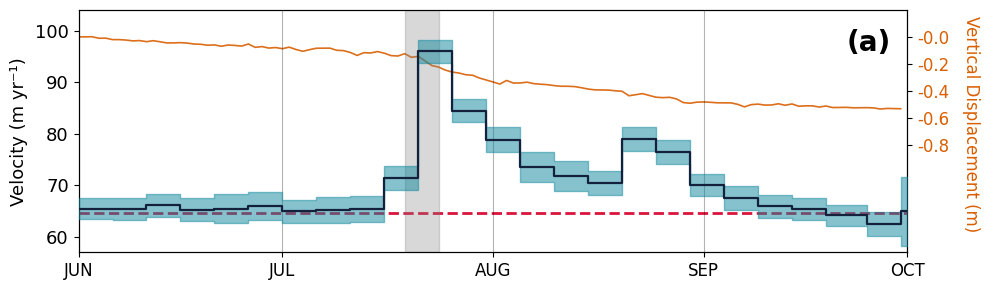

In [ ]:
# Plot ice velocity and vertical displacement at LEV6 (K-Transect) between 01-06-2023 and 01-10-2023.

fig, ax_vel = plt.subplots(figsize=(10, 3)) 
# --- (ax_vel): Velocity and Uncertainty (LEFT Y-AXIS) ---
ax_vel.plot(vel_filtered.index, vel_filtered[value_column], color=velocity_colour, drawstyle='steps-post', linewidth=1.6, zorder=5)
y_lower = vel_filtered[value_column] - vel_filtered[uncertainty_column]
y_upper = vel_filtered[value_column] + vel_filtered[uncertainty_column]
ax_vel.fill_between(vel_filtered.index, y_lower, y_upper, color=uncertainty_colour, step='post', alpha=0.5, zorder=3)
ax_vel.set_ylim(57, 104)
ax_vel.set_ylabel('Velocity (m yr⁻¹)', fontsize=13, labelpad=5) #
ax_vel.tick_params(axis='y', labelsize=13) # CHANGED: color
ax_vel.set_xlim(pd.to_datetime(start_date), pd.to_datetime(end_date))
ax_vel.axhline(y=64.7, color='crimson', linestyle='--', linewidth=2, zorder=0, label='Mean Winter Velocity\n(64.7 m yr⁻¹)')

# --- (ax_disp): Uplift (RIGHT Y-AXIS) ---
ax_disp = ax_vel.twinx()
ax_vel.set_zorder(ax_disp.get_zorder() + 1)
ax_vel.patch.set_visible(False)
ax_disp.plot(xyz_filtered_daily.index, xyz_filtered_daily['z_m_relative'].interpolate(method='linear'), color=uplift_colour, linewidth=1.2, alpha=0.9, zorder=1)
ax_disp.set_ylim(-1.6, 0.2) 
ax_disp.set_yticks([-0.0, -0.2, -0.4, -0.6, -0.8])
ax_disp.set_yticklabels(['-0.0', '-0.2', '-0.4', '-0.6', '-0.8'])
ax_disp.set_ylabel('Vertical Displacement (m)', fontsize=12, color=uplift_colour, y=0.53, rotation=270, labelpad=22)
ax_disp.tick_params(axis='y', labelcolor=uplift_colour, labelsize=12) 
ax_disp.text(0.98, 0.92, '(a)', transform=ax_disp.transAxes, fontsize=20, fontweight='bold', ha='right', va='top', color='black')

# shade plot between 19-07-2023 and 24-07-2023
shade_start = pd.to_datetime('2023-07-19')
shade_end = pd.to_datetime('2023-07-24')
ax_vel.axvspan(shade_start, shade_end, color='grey', alpha=0.3, zorder=0)

# X-axis formatting
ax_vel.xaxis.set_major_locator(mdates.MonthLocator())
def upper_month_formatter(x, pos):
    """Formats a numeric date 'x' as an uppercase 3-letter month."""
    return mdates.num2date(x).strftime('%b').upper()
ax_vel.xaxis.set_major_formatter(ticker.FuncFormatter(upper_month_formatter))
ax_vel.tick_params(axis='x', which='major', labelsize=12)
ax_vel.grid(axis='x', linestyle='-', color='black', alpha=0.3)

fig.tight_layout()
plt.show()